# Final model - **DINOv2**
### Chosen after testing with the ResNet50 model frozen and finetuned, and finding that the accuracy was much lower than expected.
<br>
The bottleneck was the frozen backbone/model of choice, during prelim testing and validation frozen-backbone DINOv2 (no finetuned head) increased accuracy by almost 30% compared to the fine-tuned ResNet50 model 

## Setup & Config

In [1]:
from huggingface_hub import login
import torch.nn as nn
from torchvision import models
login()

In [2]:
import os, json, random, hashlib, copy, time
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"

import torch

SEED = 42
BASE = Path.home() / "plant_project"  #local, copy results to drive later
RAW_ROOT = BASE / "plants"  # reuses the images you already downloaded
SPLIT_CSV = BASE / "species_split.csv"
ROWS_JSON = BASE / "species_urls.json"
CKPT_DIR = BASE / "checkpoints"
RESULTS_DIR = BASE / "results"
for p in (BASE, RAW_ROOT, CKPT_DIR, RESULTS_DIR):
    p.mkdir(parents=True, exist_ok=True)
    
PER_SPECIES = 100
MIN_PER_CLASS = 30
random.seed(SEED); np.random.seed(SEED)

device = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available() else "cpu")
use_amp = device == "cuda"
print("device:", device, "| project folder:", BASE)

device: mps | project folder: /Users/zurimckee/plant_project


## List of Species and Availability Scan
Drafts list of everyday plants that should correlate with the class plant-picture dataset. Will be edited once the team agrees on species list.
<br> 

The scan streams the HuggingFace dataset and reports how many images exist for each candidate in the scanned window, and saves URLs to Drive.

Names are matched on genus + species (first two words, case-insensitive). Counts are for the scanned sample, not the whole dataset. Houseplants may be thinly covered because GBIF is mostly wild observations.

In [3]:
CANDIDATES = [
    # houseplants
    "Epipremnum aureum", "Monstera deliciosa", "Dracaena trifasciata", "Chlorophytum comosum",
    "Spathiphyllum wallisii", "Aloe vera", "Crassula ovata", "Ficus elastica", "Ficus lyrata",
    "Zamioculcas zamiifolia", "Nephrolepis exaltata", "Hedera helix", "Tradescantia zebrina",
    "Dieffenbachia seguine", "Aglaonema commutatum", "Schlumbergera truncata",
    "Echeveria elegans", "Saintpaulia ionantha", "Philodendron hederaceum",
    # trees
    "Quercus robur", "Quercus alba", "Acer rubrum", "Acer saccharum", "Acer platanoides",
    "Betula pendula", "Pinus sylvestris", "Pinus strobus", "Fraxinus americana",
    "Liriodendron tulipifera", "Platanus occidentalis", "Ginkgo biloba", "Cornus florida",
    "Salix babylonica", "Magnolia grandiflora",
    # shrubs / common garden
    "Hydrangea macrophylla", "Buxus sempervirens", "Rhododendron ponticum", "Rosa canina",
    "Forsythia suspensa", "Syringa vulgaris", "Ilex aquifolium", "Taxus baccata",
    "Lavandula angustifolia", "Taraxacum officinale",
]
SCAN_LIMIT = 3_000_000   # rows to scan; lower it if this takes too long

## Split data
Stratified 70/15/15 saved to a csv so not overwritten by accident.

Baseline and fine-tuned models both read this file, so they are always compared on identical test images. The manifest is never overwritten unless you pass force=True.

Splits
- 70% train
- 15% validation
- 15% test

In [4]:
from sklearn.model_selection import train_test_split

def build_manifest(root, out_csv, min_per_class=MIN_PER_CLASS, seed=SEED, force=False):
    out_csv = Path(out_csv)
    if out_csv.exists() and not force:
        print("loading existing manifest", out_csv)
        return pd.read_csv(out_csv)
    recs = []
    for d in sorted(Path(root).iterdir()):
        if not d.is_dir():
            continue
        files = [f for f in d.iterdir() if f.suffix.lower() in {".jpg", ".jpeg", ".png"}]
        if len(files) < min_per_class:
            print(f"dropping {d.name}: only {len(files)} images")
            continue
        recs += [(str(f), d.name) for f in files]
    df = pd.DataFrame(recs, columns=["path", "label"])
    tr, tmp = train_test_split(df.index, test_size=0.30, stratify=df.label, random_state=seed)
    va, te = train_test_split(tmp, test_size=0.50, stratify=df.label[tmp], random_state=seed)
    df["split"] = "train"
    df.loc[va, "split"] = "val"
    df.loc[te, "split"] = "test"
    df.to_csv(out_csv, index=False)
    print(df.split.value_counts().to_dict(), "|", df.label.nunique(), "classes")
    return df

manifest = build_manifest(RAW_ROOT, SPLIT_CSV)

loading existing manifest /Users/zurimckee/plant_project/species_split.csv


## Fine tuning the DINO model 

In [5]:
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay, recall_score
import contextlib\

def amp_ctx():
    return (torch.autocast(device_type="cuda", dtype=torch.float16)
            if use_amp else contextlib.nullcontext())


MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.5, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.3, 0.3, 0.3, 0.05),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([
    transforms.Resize(256), transforms.CenterCrop(224),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class ManifestDS(Dataset):
    def __init__(self, df, class_to_idx, tf):
        self.paths = df.path.tolist()
        self.y = [class_to_idx[l] for l in df.label]
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert("RGB")), self.y[i]

def make_loaders(df, classes, batch=32):
    c2i = {c: i for i, c in enumerate(classes)}
    mk = lambda split, tf, shuffle, bs: DataLoader(
        ManifestDS(df[df.split == split], c2i, tf), batch_size=bs, shuffle=shuffle, num_workers=0)
    return mk("train", train_tf, True, batch), mk("val", eval_tf, False, 64), mk("test", eval_tf, False, 64)

def build_model(n_classes):
    m = models.resnet50(weights="IMAGENET1K_V2")
    m.fc = nn.Linear(m.fc.in_features, n_classes)
    return m

def set_backbone_trainable(model, flag):
    for name, p in model.named_parameters():
        p.requires_grad = flag or name.startswith("fc.")

def run_epoch(model, dl, opt=None, scaler=None, freeze_bn=False):
    train = opt is not None
    model.train(train)
    if train and freeze_bn:               # truly frozen backbone: keep BatchNorm stats fixed
        for m in model.modules():
            if isinstance(m, nn.BatchNorm2d):
                m.eval()
    loss_sum, n, ys, ps = 0.0, 0, [], []
    with torch.set_grad_enabled(train):
        for x, t in dl:
            x, t = x.to(device), t.to(device)
            with amp_ctx():
                out = model(x)
                loss = nn.functional.cross_entropy(out, t)
            if train:
                opt.zero_grad()
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            loss_sum += loss.item() * len(t); n += len(t)
            ys += t.tolist(); ps += out.argmax(1).tolist()
    acc = float(np.mean(np.array(ys) == np.array(ps)))
    return loss_sum / n, acc, f1_score(ys, ps, average="macro")

def fit(model, train_dl, val_dl, epochs, lr, freeze_backbone):
    set_backbone_trainable(model, not freeze_backbone)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    best_f1, best_state = -1, None
    for e in range(epochs):
        t0 = time.time()
        tr = run_epoch(model, train_dl, opt, scaler, freeze_bn=freeze_backbone)
        va = run_epoch(model, val_dl)
        sched.step()
        print(f"ep {e+1}/{epochs}  train loss {tr[0]:.3f} acc {tr[1]:.3f} | "
              f"val loss {va[0]:.3f} acc {va[1]:.3f} f1 {va[2]:.3f}  ({time.time()-t0:.0f}s)")
        if va[2] > best_f1:      # choose checkpoint on VALIDATION macro F1, never on test
            best_f1 = va[2]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return best_f1

@torch.no_grad()
def collect_preds(model, dl):
    model.eval()
    ys, ps = [], []
    for x, t in dl:
        with amp_ctx():
            out = model(x.to(device))
        ys += t.tolist(); ps += out.argmax(1).tolist()
    return np.array(ys), np.array(ps)

def evaluate(model, dl, classes, name):
    """Accuracy, macro F1, per-class recall, confusion matrix. Saved to Drive."""
    y, p = collect_preds(model, dl)
    labels = list(range(len(classes)))
    res = {
        "name": name, "n": int(len(y)),
        "accuracy": float((y == p).mean()),
        "macro_f1": float(f1_score(y, p, average="macro", labels=labels, zero_division=0)),
        "per_class_recall": {c: float(r) for c, r in zip(
            classes, recall_score(y, p, labels=labels, average=None, zero_division=0))},
    }
    # healthy-vs-diseased view (only if class names contain 'healthy')
    healthy_idx = {i for i, c in enumerate(classes) if "healthy" in c.lower()}
    if healthy_idx:
        yt = np.array([0 if v in healthy_idx else 1 for v in y])   # 1 = diseased
        yp = np.array([0 if v in healthy_idx else 1 for v in p])
        res["binary_health"] = {"accuracy": float((yt == yp).mean()),
                                "diseased_recall": float(((yt == 1) & (yp == 1)).sum() / max((yt == 1).sum(), 1))}
    json.dump(res, open(RESULTS_DIR / f"{name}.json", "w"), indent=2)
    cm = confusion_matrix(y, p, labels=labels)
    fig, ax = plt.subplots(figsize=(max(6, len(classes) * 0.4),) * 2)
    ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, xticks_rotation=90, colorbar=False)
    fig.tight_layout(); fig.savefig(RESULTS_DIR / f"{name}_confusion.png", dpi=120); plt.show()
    print(f"{name}: acc {res['accuracy']:.3f}  macro-F1 {res['macro_f1']:.3f}  (n={res['n']})")
    if "binary_health" in res:
        print("  healthy-vs-diseased:", res["binary_health"])
    return res

def save_ckpt(model, classes, name):
    torch.save({"model": model.state_dict(), "classes": classes}, CKPT_DIR / f"{name}.pt")

In [6]:
from transformers import AutoModel

class DinoClassifier(nn.Module):
    """DINOv2 backbone + linear head. The head is named `fc`, so set_backbone_trainable,
    fit, save_ckpt and evaluate all work unchanged."""
    def __init__(self, n_classes, name="facebook/dinov2-small"):
        super().__init__()
        self.backbone = AutoModel.from_pretrained(name)
        self.fc = nn.Linear(self.backbone.config.hidden_size, n_classes)
    def forward(self, x):
        return self.fc(self.backbone(pixel_values=x).pooler_output)

def run_pipeline_v2(root, tag, csv_path, builder, head_epochs=10, ft_epochs=10,
                    head_lr=1e-3, ft_lr=1e-4, batch=32, eval_split="val"):
    df = build_manifest(root, csv_path)
    classes = sorted(df.label.unique())
    train_dl, val_dl, test_dl = make_loaders(df, classes, batch)
    eval_dl = {"val": val_dl, "test": test_dl}[eval_split]
    model = builder(len(classes)).to(device)

    print("=== Stage 1: frozen backbone, head only ===")
    fit(model, train_dl, val_dl, head_epochs, lr=head_lr, freeze_backbone=True)
    save_ckpt(model, classes, f"{tag}_baseline")
    base = evaluate(model, eval_dl, classes, f"{tag}_baseline_{eval_split}")

    print("=== Stage 2: fine-tune all layers ===")
    fit(model, train_dl, val_dl, ft_epochs, lr=ft_lr, freeze_backbone=False)
    save_ckpt(model, classes, f"{tag}_finetuned")
    ft = evaluate(model, eval_dl, classes, f"{tag}_finetuned_{eval_split}")

    table = pd.DataFrame([
        {"model": "frozen head", "accuracy": base["accuracy"], "macro_f1": base["macro_f1"]},
        {"model": "fine-tuned",  "accuracy": ft["accuracy"],   "macro_f1": ft["macro_f1"]}])
    print(table.to_string(index=False))
    table.to_csv(RESULTS_DIR / f"{tag}_comparison_{eval_split}.csv", index=False)
    return model, classes

/Users/zurimckee/zuriscodingstuff/plantmodeltraining/.venv/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


loading existing manifest /Users/zurimckee/plant_project/species_split.csv


W1120 17:22:45.690000 27763 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 223/223 [00:00<00:00, 12054.15it/s]


=== Stage 1: frozen backbone, head only ===
ep 1/1  train loss 1.906 acc 0.479 | val loss 0.953 acc 0.716 f1 0.719  (54s)


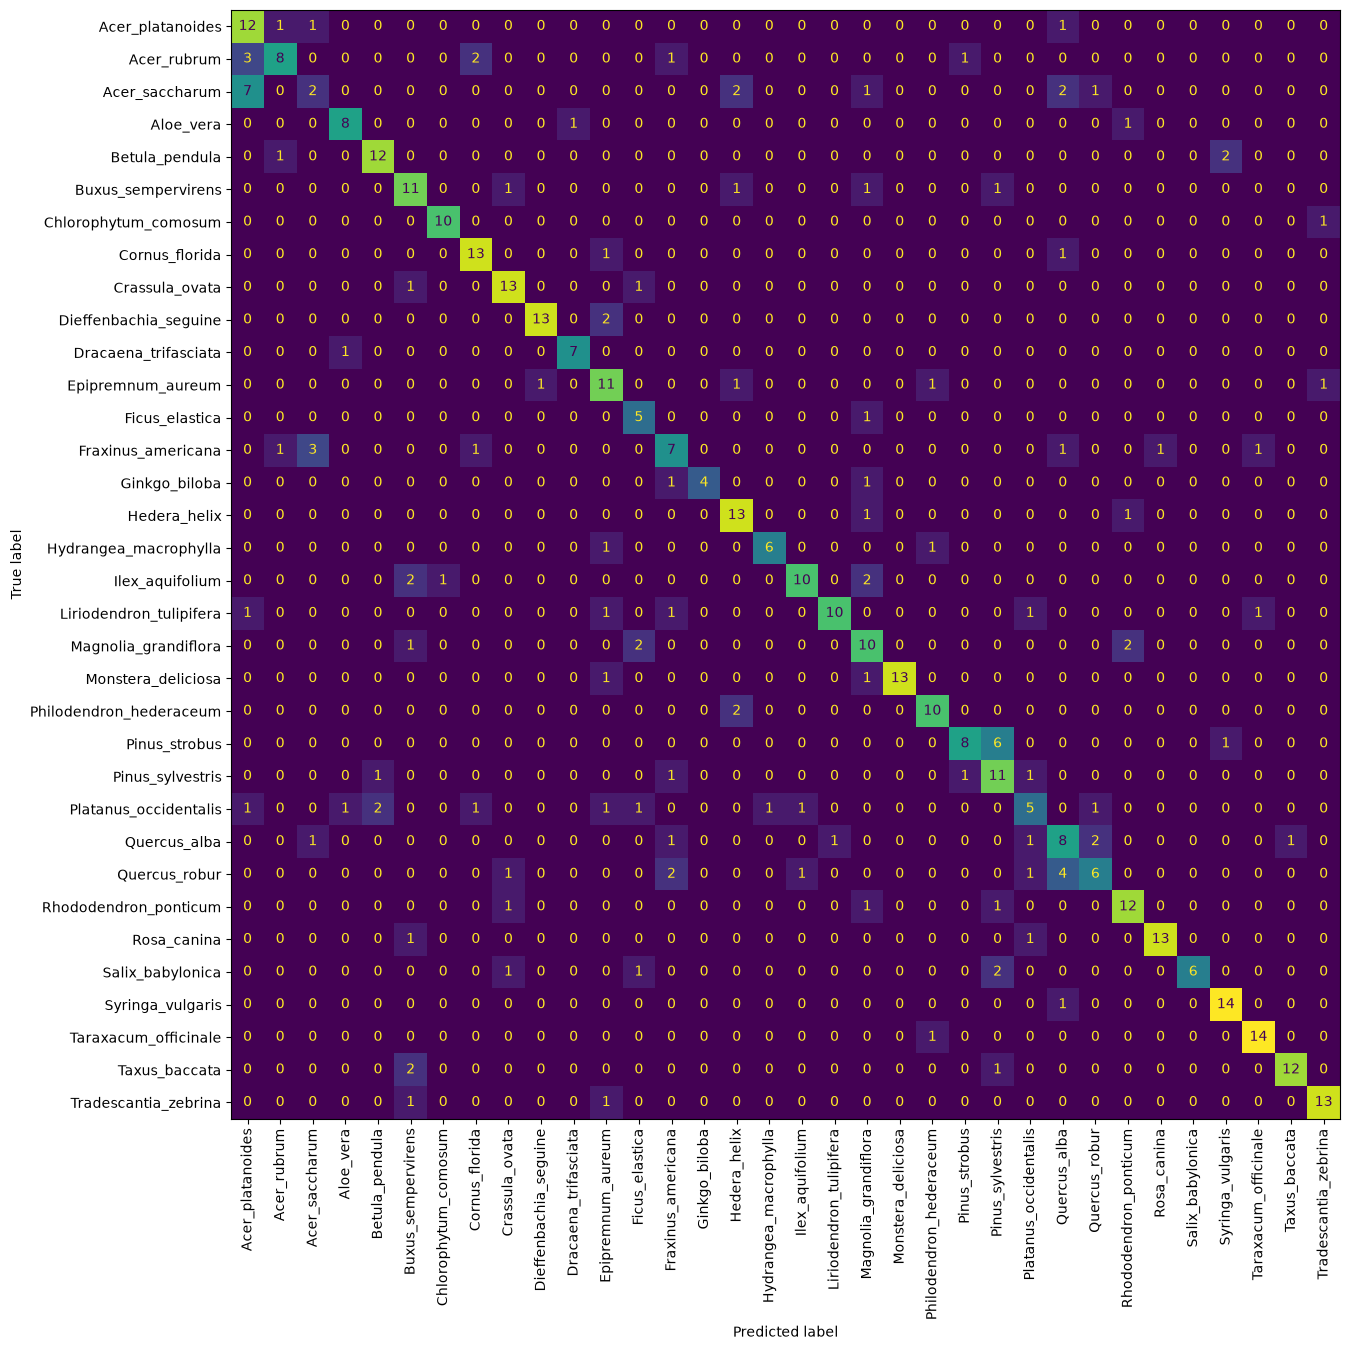

dino_dry_baseline_val: acc 0.716  macro-F1 0.719  (n=461)
=== Stage 2: fine-tune all layers ===
ep 1/1  train loss 0.908 acc 0.732 | val loss 0.751 acc 0.770 f1 0.773  (90s)


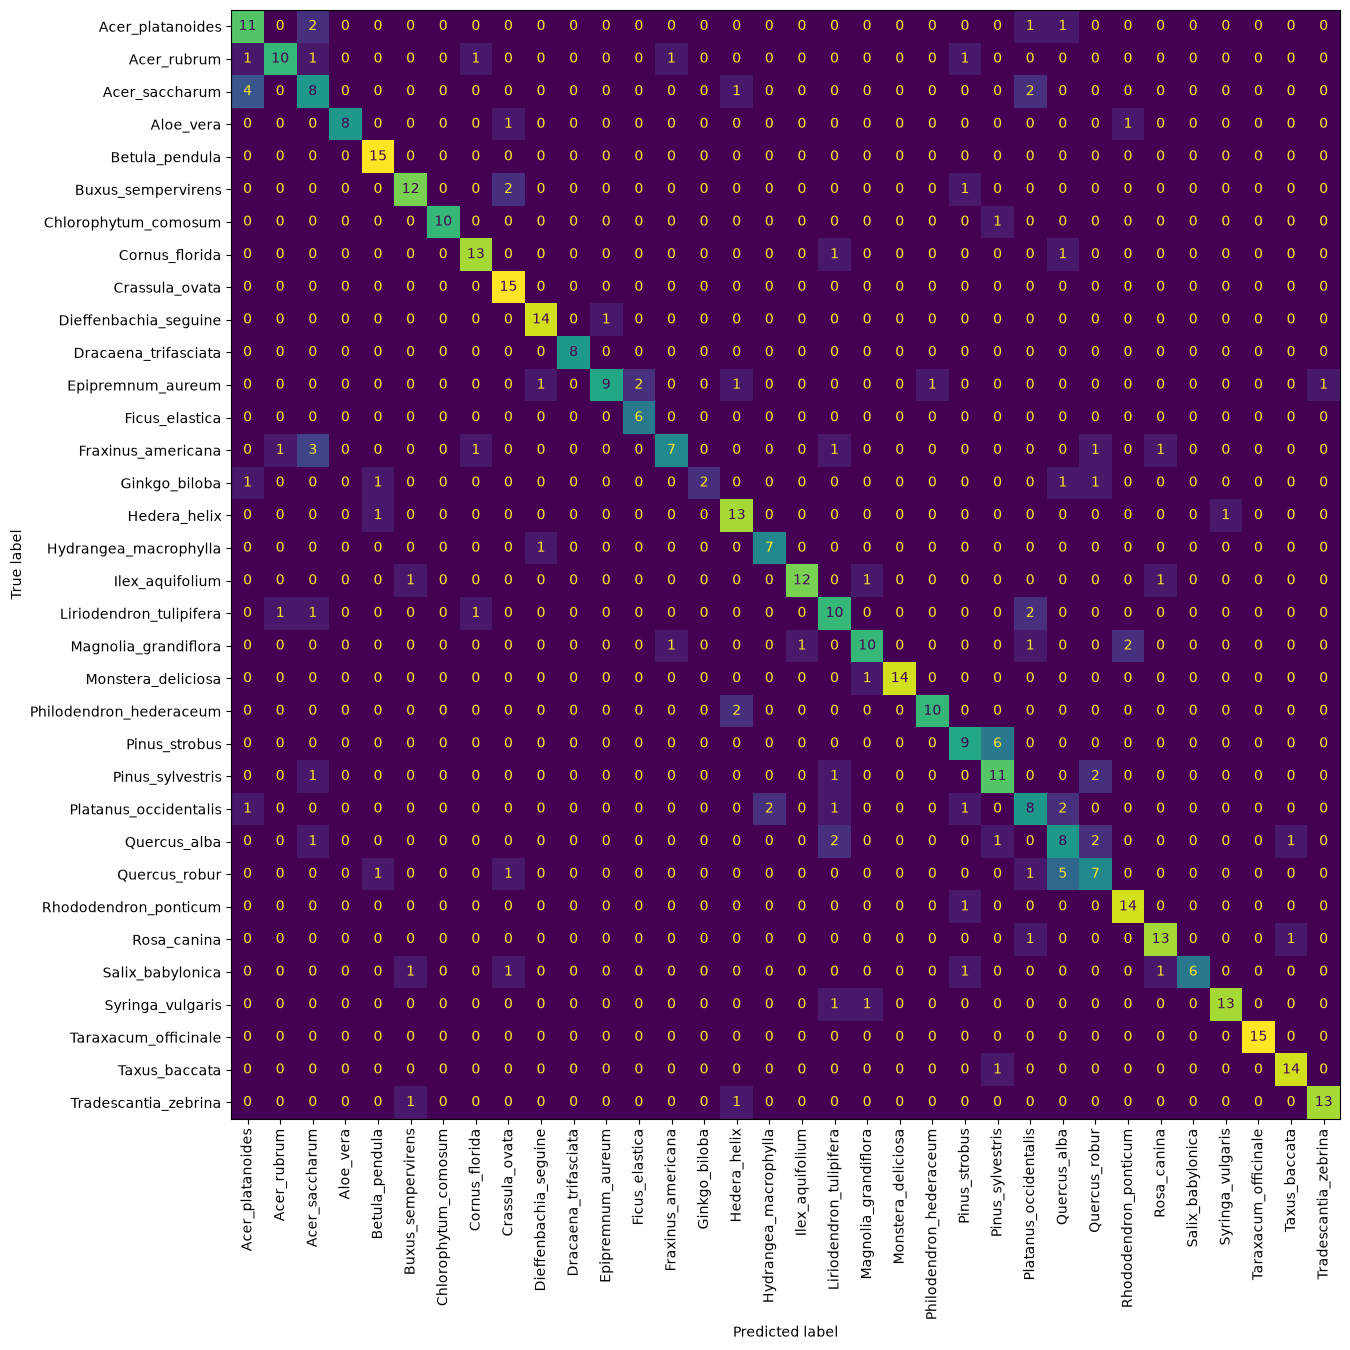

dino_dry_finetuned_val: acc 0.770  macro-F1 0.773  (n=461)
      model  accuracy  macro_f1
frozen head  0.715835  0.718642
 fine-tuned  0.770065  0.772662


(DinoClassifier(
   (backbone): Dinov2Model(
     (embeddings): Dinov2Embeddings(
       (patch_embeddings): Dinov2PatchEmbeddings(
         (projection): Conv2d(3, 384, kernel_size=(14, 14), stride=(14, 14))
       )
       (dropout): Dropout(p=0.0, inplace=False)
     )
     (encoder): Dinov2Encoder(
       (layer): ModuleList(
         (0-11): 12 x Dinov2Layer(
           (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True, bias=True)
           (attention): Dinov2Attention(
             (q_proj): Linear(in_features=384, out_features=384, bias=True)
             (k_proj): Linear(in_features=384, out_features=384, bias=True)
             (v_proj): Linear(in_features=384, out_features=384, bias=True)
             (o_proj): Linear(in_features=384, out_features=384, bias=True)
           )
           (layer_scale1): Dinov2LayerScale()
           (drop_path): Identity()
           (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True, bias=True)
           (mlp): Dinov2

In [ ]:
# dry run first, to check it works and see seconds per epoch
m, c = run_pipeline_v2(RAW_ROOT, "dino_dry", SPLIT_CSV, builder=lambda n: DinoClassifier(n),
                head_epochs=1, ft_epochs=1, ft_lr=1e-5)


loading existing manifest /Users/zurimckee/plant_project/species_split.csv


Loading weights: 100%|██████████| 223/223 [00:00<00:00, 11480.67it/s]


=== Stage 1: frozen backbone, head only ===
ep 1/5  train loss 1.894 acc 0.484 | val loss 0.982 acc 0.716 f1 0.713  (53s)
ep 2/5  train loss 0.795 acc 0.773 | val loss 0.753 acc 0.790 f1 0.787  (53s)
ep 3/5  train loss 0.616 acc 0.827 | val loss 0.678 acc 0.807 f1 0.809  (53s)
ep 4/5  train loss 0.514 acc 0.867 | val loss 0.652 acc 0.809 f1 0.812  (53s)
ep 5/5  train loss 0.493 acc 0.869 | val loss 0.642 acc 0.813 f1 0.817  (53s)


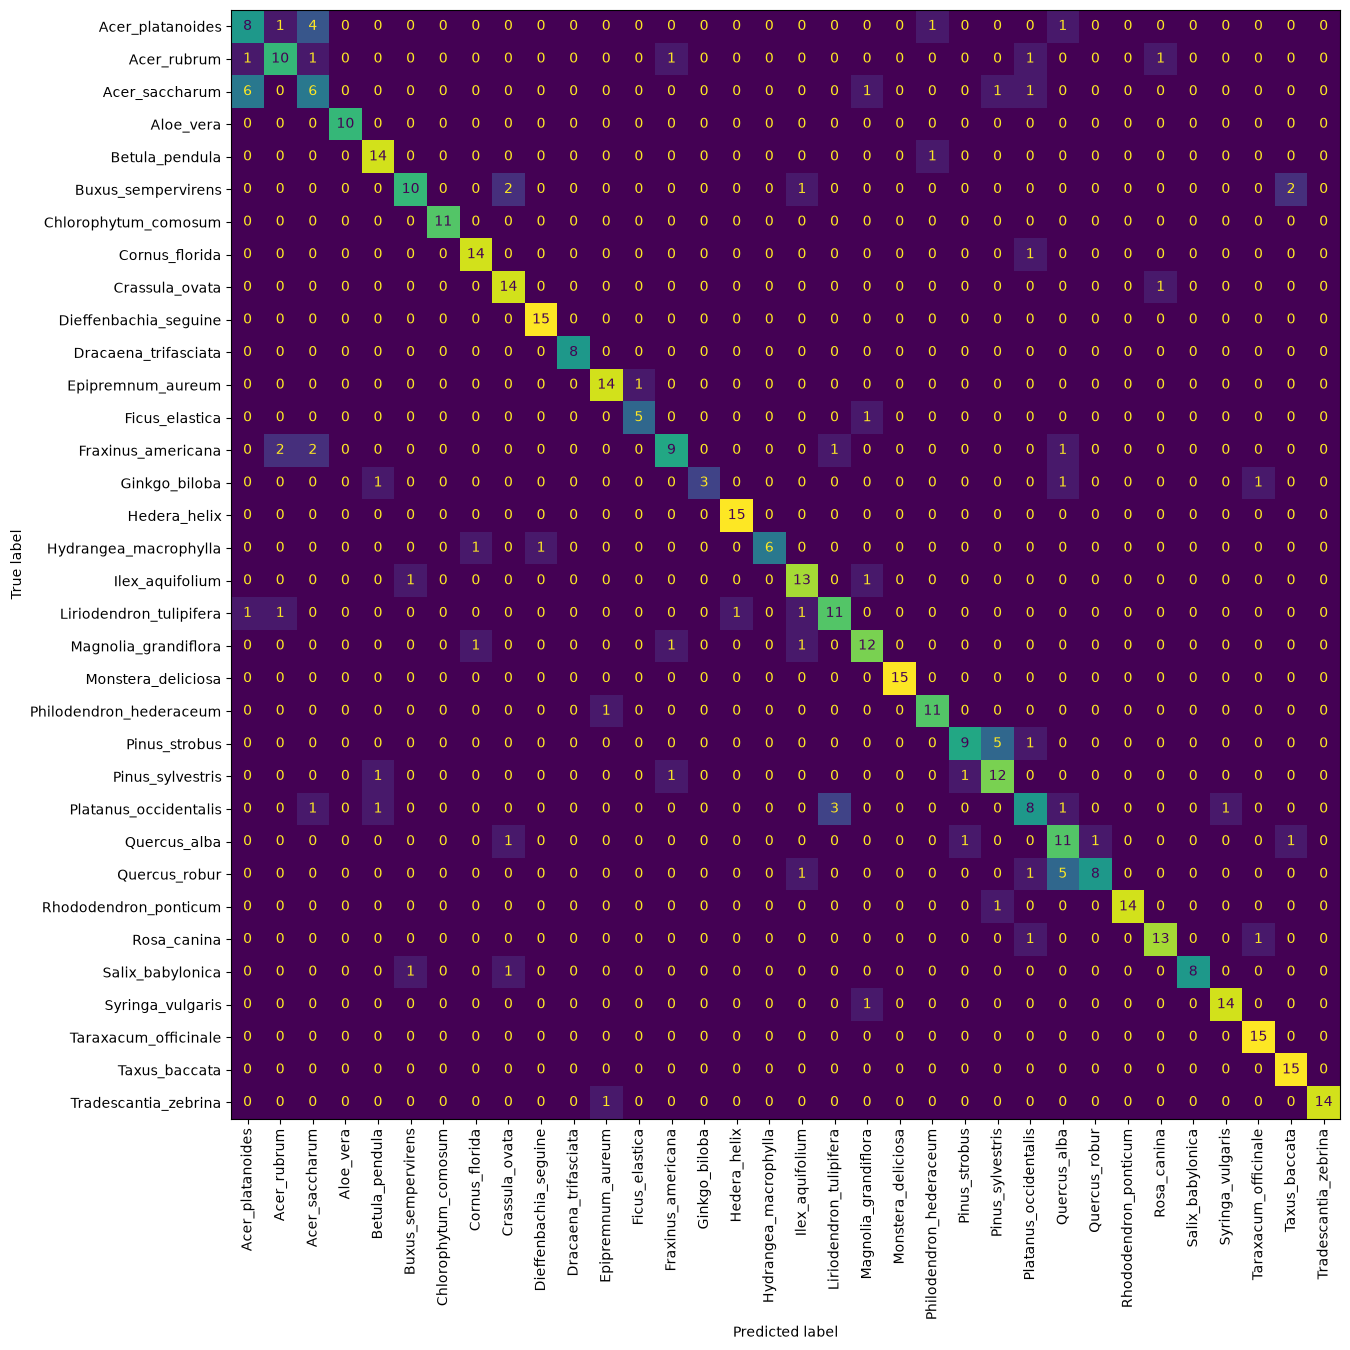

species_dino_baseline_val: acc 0.813  macro-F1 0.817  (n=461)
=== Stage 2: fine-tune all layers ===
ep 1/10  train loss 0.638 acc 0.803 | val loss 0.631 acc 0.805 f1 0.803  (91s)
ep 2/10  train loss 0.409 acc 0.878 | val loss 0.620 acc 0.816 f1 0.820  (99s)
ep 3/10  train loss 0.283 acc 0.922 | val loss 0.552 acc 0.831 f1 0.831  (102s)
ep 4/10  train loss 0.201 acc 0.946 | val loss 0.569 acc 0.813 f1 0.813  (111s)
ep 5/10  train loss 0.150 acc 0.966 | val loss 0.527 acc 0.831 f1 0.834  (113s)
ep 6/10  train loss 0.111 acc 0.976 | val loss 0.526 acc 0.831 f1 0.831  (105s)
ep 7/10  train loss 0.072 acc 0.994 | val loss 0.484 acc 0.839 f1 0.840  (109s)
ep 8/10  train loss 0.059 acc 0.994 | val loss 0.485 acc 0.839 f1 0.840  (102s)
ep 9/10  train loss 0.051 acc 0.997 | val loss 0.492 acc 0.846 f1 0.845  (103s)
ep 10/10  train loss 0.050 acc 0.996 | val loss 0.487 acc 0.846 f1 0.846  (101s)


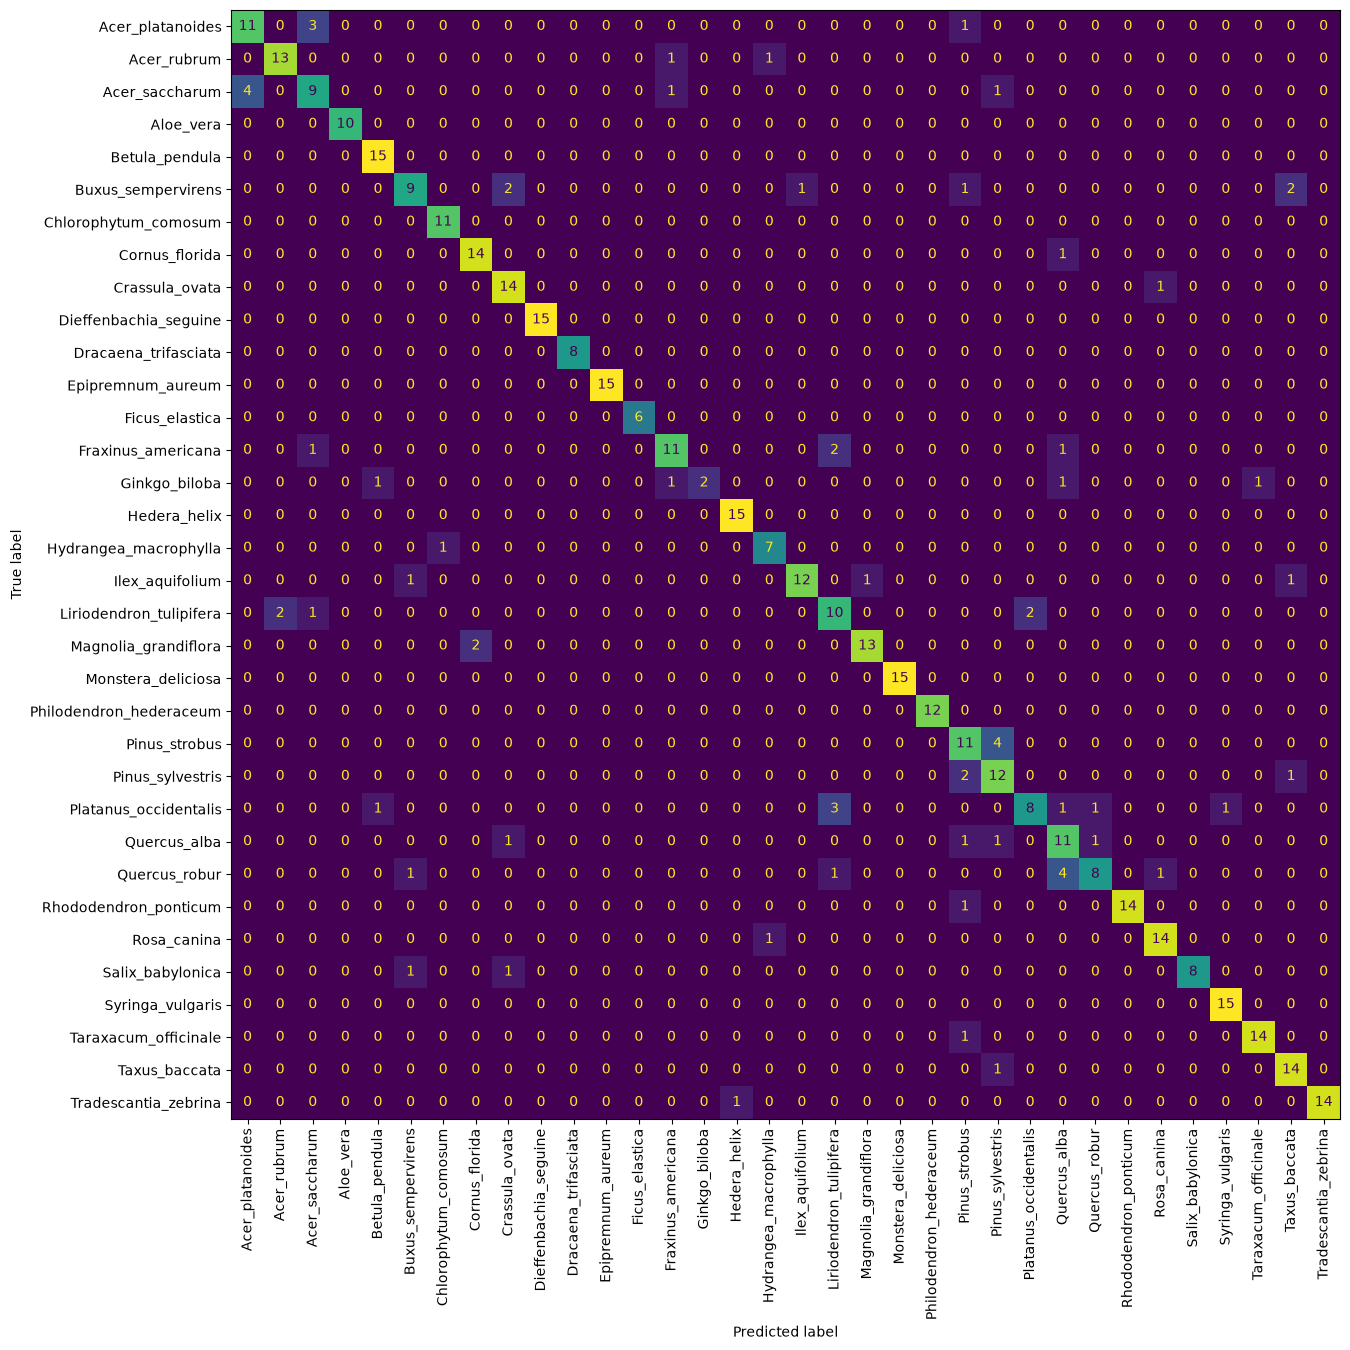

species_dino_finetuned_val: acc 0.846  macro-F1 0.846  (n=461)
      model  accuracy  macro_f1
frozen head  0.813449  0.816507
 fine-tuned  0.845987  0.845710


In [12]:
# real run
dino_model, dino_classes = run_pipeline_v2(
    RAW_ROOT, "species_dino", SPLIT_CSV,
    builder=lambda n: DinoClassifier(n), head_epochs=5, ft_epochs=10, ft_lr=1e-5)

## Comparing ResNet and DINOv2 performance

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

manifest = build_manifest(RAW_ROOT, SPLIT_CSV)          # loads the saved split, does not rebuild
classes = sorted(manifest.label.unique())
c2i = {c: i for i, c in enumerate(classes)}

@torch.no_grad()
def extract_features(backbone, df, batch=64, out_fn=None):
    """Frozen features, clean (non-augmented) transform. out_fn maps model output -> (B, D) tensor."""
    backbone.eval().to(device)
    dl = DataLoader(ManifestDS(df, c2i, eval_tf), batch_size=batch, num_workers=0)
    feats, ys = [], []
    for x, t in dl:
        o = backbone(x.to(device))
        o = out_fn(o) if out_fn else o
        feats.append(o.float().cpu()); ys += t.tolist()
    return torch.cat(feats).numpy(), np.array(ys)

def get_features(name, backbone, out_fn=None):
    """Extract train + val features once and cache to disk. The test split is deliberately not touched."""
    cache = BASE / f"feats_{name}.npz"
    if cache.exists():
        d = np.load(cache); print("loaded cached features:", cache.name)
        return d["Xtr"], d["ytr"], d["Xva"], d["yva"]
    Xtr, ytr = extract_features(backbone, manifest[manifest.split == "train"], out_fn=out_fn)
    Xva, yva = extract_features(backbone, manifest[manifest.split == "val"], out_fn=out_fn)
    np.savez(cache, Xtr=Xtr, ytr=ytr, Xva=Xva, yva=yva)
    print("saved", cache.name, Xtr.shape, Xva.shape)
    return Xtr, ytr, Xva, yva

# ImageNet ResNet50 (same starting weights as your baseline), classifier head removed
rn = models.resnet50(weights="IMAGENET1K_V2")
rn.fc = nn.Identity()
feats_rn50 = get_features("resnet50_imagenet", rn)

loading existing manifest /Users/zurimckee/plant_project/species_split.csv
loaded cached features: feats_resnet50_imagenet.npz


In [8]:
# DINOv2-small frozen features (loads ~/plant_project/feats_dinov2_small.npz if cached)
from transformers import AutoModel

dino = AutoModel.from_pretrained("facebook/dinov2-small")
feats_dino = get_features("dinov2_small", dino, out_fn=lambda o: o.pooler_output)
print(feats_dino[0].shape)   # expect (2151, 384)

W1120 18:26:25.119000 41923 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 223/223 [00:00<00:00, 23670.25it/s]

loaded cached features: feats_dinov2_small.npz
(2151, 384)


In [9]:
from sklearn.metrics import f1_score

def sweep_C(feats, Cs=(0.01, 0.03, 0.1, 0.3, 1.0)):
    Xtr, ytr, Xva, yva = feats
    sc = StandardScaler().fit(Xtr)
    out = []
    for C in Cs:
        p = LogisticRegression(C=C, max_iter=3000).fit(sc.transform(Xtr), ytr).predict(sc.transform(Xva))
        out.append({"C": C, "val_acc": round(float((p == yva).mean()), 3),
                    "val_f1": round(float(f1_score(yva, p, average="macro")), 3)})
    return pd.DataFrame(out)

print("ResNet50");     print(sweep_C(feats_rn50).to_string(index=False))
print("DINOv2-small"); print(sweep_C(feats_dino).to_string(index=False))

ResNet50
   C  val_acc  val_f1
0.01    0.584   0.581
0.03    0.594   0.597
0.10    0.599   0.603
0.30    0.590   0.592
1.00    0.588   0.591
DINOv2-small
   C  val_acc  val_f1
0.01    0.844   0.854
0.03    0.863   0.871
0.10    0.866   0.875
0.30    0.863   0.871
1.00    0.866   0.872


frac 0.25 seed 0: n=537  val acc 0.449  f1 0.444
frac 0.25 seed 1: n=537  val acc 0.436  f1 0.431
frac 0.25 seed 2: n=537  val acc 0.449  f1 0.440
frac 0.50 seed 0: n=1075  val acc 0.531  f1 0.534
frac 0.50 seed 1: n=1075  val acc 0.534  f1 0.531
frac 0.50 seed 2: n=1075  val acc 0.538  f1 0.528
frac 0.75 seed 0: n=1613  val acc 0.553  f1 0.547
frac 0.75 seed 1: n=1613  val acc 0.568  f1 0.570
frac 0.75 seed 2: n=1613  val acc 0.575  f1 0.567
frac 1.00 seed 0: n=2151  val acc 0.599  f1 0.603
frac 0.25 seed 0: n=537  val acc 0.781  f1 0.793
frac 0.25 seed 1: n=537  val acc 0.761  f1 0.774
frac 0.25 seed 2: n=537  val acc 0.761  f1 0.761
frac 0.50 seed 0: n=1075  val acc 0.816  f1 0.822
frac 0.50 seed 1: n=1075  val acc 0.820  f1 0.830
frac 0.50 seed 2: n=1075  val acc 0.829  f1 0.836
frac 0.75 seed 0: n=1613  val acc 0.837  f1 0.848
frac 0.75 seed 1: n=1613  val acc 0.833  f1 0.844
frac 0.75 seed 2: n=1613  val acc 0.839  f1 0.851
frac 1.00 seed 0: n=2151  val acc 0.866  f1 0.875


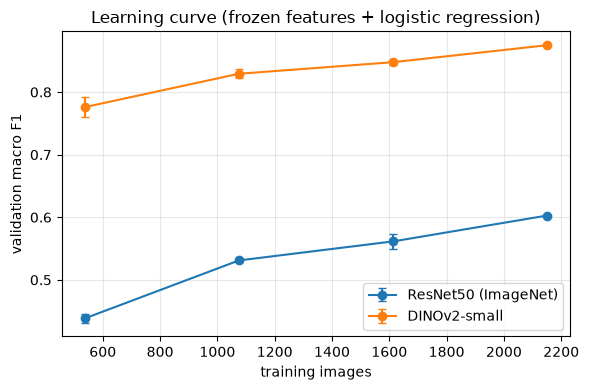

In [10]:
# Learning curves: frozen features + logistic regression at 25/50/75/100% of the training set
def learning_curve(feats, fracs=(0.25, 0.5, 0.75, 1.0), seeds=(0, 1, 2), C=0.1):
    Xtr, ytr, Xva, yva = feats
    sc = StandardScaler().fit(Xtr)
    Xtr_s, Xva_s = sc.transform(Xtr), sc.transform(Xva)
    rows = []
    for f in fracs:
        for s in (seeds if f < 1.0 else seeds[:1]):          # 100% has no sampling randomness
            if f < 1.0:
                idx, _ = train_test_split(np.arange(len(ytr)), train_size=f, stratify=ytr, random_state=s)
            else:
                idx = np.arange(len(ytr))
            clf = LogisticRegression(C=C, max_iter=2000).fit(Xtr_s[idx], ytr[idx])
            p = clf.predict(Xva_s)
            rows.append({"frac": f, "seed": s, "n_train": len(idx),
                         "acc": float((p == yva).mean()),
                         "macro_f1": float(f1_score(yva, p, average="macro"))})
            print(f"frac {f:.2f} seed {s}: n={len(idx)}  val acc {rows[-1]['acc']:.3f}  f1 {rows[-1]['macro_f1']:.3f}")
    return pd.DataFrame(rows)

def plot_curves(results, path=None):
    fig, ax = plt.subplots(figsize=(6, 4))
    for name, df in results.items():
        g = df.groupby("n_train").macro_f1.agg(["mean", "std"]).fillna(0)
        ax.errorbar(g.index, g["mean"], yerr=g["std"], marker="o", capsize=3, label=name)
    ax.set_xlabel("training images"); ax.set_ylabel("validation macro F1")
    ax.set_title("Learning curve (frozen features + logistic regression)")
    ax.grid(alpha=.3); ax.legend()
    fig.tight_layout()
    if path: fig.savefig(path, dpi=120)
    plt.show()

results = {"ResNet50 (ImageNet)": learning_curve(feats_rn50),
           "DINOv2-small": learning_curve(feats_dino)}
plot_curves(results, RESULTS_DIR / "learning_curve_compare.png")

Loading weights: 100%|██████████| 223/223 [00:00<00:00, 11584.47it/s]


loaded cached features: feats_dinov2_base.npz
frac 0.25 seed 0: n=537  val acc 0.839  f1 0.851
frac 0.25 seed 1: n=537  val acc 0.813  f1 0.821
frac 0.25 seed 2: n=537  val acc 0.811  f1 0.817
frac 0.50 seed 0: n=1075  val acc 0.861  f1 0.871
frac 0.50 seed 1: n=1075  val acc 0.857  f1 0.863
frac 0.50 seed 2: n=1075  val acc 0.861  f1 0.866
frac 0.75 seed 0: n=1613  val acc 0.874  f1 0.884
frac 0.75 seed 1: n=1613  val acc 0.870  f1 0.875
frac 0.75 seed 2: n=1613  val acc 0.887  f1 0.896
frac 1.00 seed 0: n=2151  val acc 0.889  f1 0.895


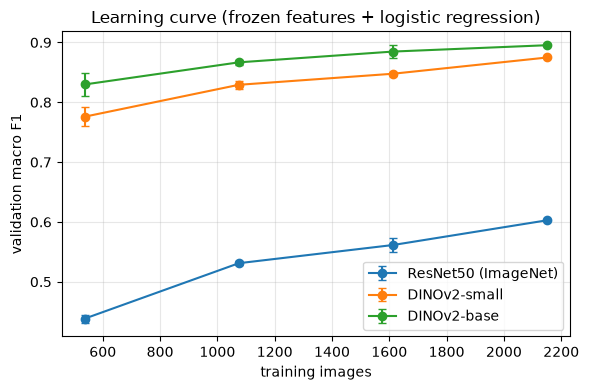

DINOv2-base
   C  val_acc  val_f1
0.01    0.879   0.885
0.03    0.889   0.895
0.10    0.889   0.895
0.30    0.892   0.897
1.00    0.892   0.897


In [11]:
dino_b = AutoModel.from_pretrained("facebook/dinov2-base")
feats_dino_b = get_features("dinov2_base", dino_b, out_fn=lambda o: o.pooler_output)
results["DINOv2-base"] = learning_curve(feats_dino_b)
plot_curves(results, RESULTS_DIR / "learning_curve_compare.png")
print("DINOv2-base"); print(sweep_C(feats_dino_b).to_string(index=False))

## Per-class check
This shows whether the maple, oak, and pine lookalikes improved, and gives top-3 accuracy.

In [12]:
Xtr, ytr, Xva, yva = feats_dino_b
sc = StandardScaler().fit(Xtr)
clf = LogisticRegression(C=0.1, max_iter=3000).fit(sc.transform(Xtr), ytr)
P = clf.predict_proba(sc.transform(Xva))
pred = P.argmax(1)
top3 = np.argsort(-P, axis=1)[:, :3]
print(f"val top-1 {np.mean(pred == yva):.3f}   top-3 {np.mean([yva[i] in top3[i] for i in range(len(yva))]):.3f}")

rows = []
for i, c in enumerate(classes):
    m = yva == i
    wrong = pred[m][pred[m] != i]
    conf = pd.Series([classes[j] for j in wrong]).value_counts().head(2)
    rows.append({"class": c, "val_n": int(m.sum()), "recall": round(float((pred[m] == i).mean()), 2),
                 "most_confused_with": ", ".join(f"{k} ({v})" for k, v in conf.items())})
print(pd.DataFrame(rows).sort_values("recall").head(12).to_string(index=False))

val top-1 0.889   top-3 0.963
                  class  val_n  recall                              most_confused_with
          Ginkgo_biloba      6    0.67                     Liriodendron_tulipifera (2)
       Pinus_sylvestris     15    0.67       Pinus_strobus (4), Fraxinus_americana (1)
           Quercus_alba     15    0.67    Quercus_robur (2), Platanus_occidentalis (1)
          Quercus_robur     15    0.73 Acer_saccharum (1), Liriodendron_tulipifera (1)
Liriodendron_tulipifera     15    0.73   Platanus_occidentalis (1), Acer_saccharum (1)
         Acer_saccharum     15    0.73        Quercus_alba (1), Fraxinus_americana (1)
  Platanus_occidentalis     15    0.80        Acer_saccharum (1), Acer_platanoides (1)
          Pinus_strobus     15    0.80                            Pinus_sylvestris (3)
            Acer_rubrum     15    0.80            Taxus_baccata (1), Pinus_strobus (1)
       Salix_babylonica     10    0.80      Buxus_sempervirens (1), Crassula_ovata (1)
       Acer_p

## Final test score and save
run once and treat that number as your report figure

In [13]:
import joblib

test_rows = manifest[manifest.split == "test"]
Xte, yte = extract_features(dino_b, test_rows, out_fn=lambda o: o.pooler_output)

sc = StandardScaler().fit(Xtr)
clf = LogisticRegression(C=0.1, max_iter=3000).fit(sc.transform(Xtr), ytr)
P = clf.predict_proba(sc.transform(Xte)); pred = P.argmax(1)
top3 = np.argsort(-P, axis=1)[:, :3]
res = {"n": int(len(yte)), "top1": float((pred == yte).mean()),
       "macro_f1": float(f1_score(yte, pred, average="macro")),
       "top3": float(np.mean([yte[i] in top3[i] for i in range(len(yte))]))}
print(res)
json.dump(res, open(RESULTS_DIR / "dinov2_base_probe_test.json", "w"), indent=2)
joblib.dump({"scaler": sc, "clf": clf, "classes": classes, "backbone": "facebook/dinov2-base"},
            CKPT_DIR / "species_dinov2_base_probe.joblib")

{'n': 461, 'top1': 0.8633405639913232, 'macro_f1': 0.8700756492807751, 'top3': 0.9479392624728851}


['/Users/zurimckee/plant_project/checkpoints/species_dinov2_base_probe.joblib']

## Load saved model for interface
The classifier is saved as checkpoints/species_dinov2_base_probe.joblib. This cell loads it and predicts.

In [ ]:
# Self-contained: runs on a fresh kernel without the cells above, so it can be copied into the interface as-is.
from pathlib import Path
import joblib
import numpy as np
import torch
from PIL import Image
from torchvision import transforms
from transformers import AutoModel

# path relative to the repo root; change it if the interface lives somewhere else
PROBE_PATH = Path("plant_project/checkpoints/species_dinov2_base_probe.joblib")

DEVICE = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available() else "cpu")

# must match eval_tf used when the training features were extracted
EVAL_TF = transforms.Compose([
    transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

class SpeciesPredictor:
    def __init__(self, path=PROBE_PATH, device=DEVICE):
        d = joblib.load(path)
        self.scaler, self.clf, self.classes = d["scaler"], d["clf"], d["classes"]
        self.device = device
        self.backbone = AutoModel.from_pretrained(d["backbone"]).eval().to(device)

    @torch.no_grad()
    def predict(self, img, k=3):
        if not isinstance(img, Image.Image):
            img = Image.open(img)
        x = EVAL_TF(img.convert("RGB")).unsqueeze(0).to(self.device)
        f = self.backbone(pixel_values=x).pooler_output.float().cpu().numpy()
        p = self.clf.predict_proba(self.scaler.transform(f))[0]
        top = np.argsort(-p)[:k]
        return {"prediction": self.classes[top[0]].replace("_", " "),
                "confidence": float(p[top[0]]),
                "top_k": [(self.classes[i].replace("_", " "), float(p[i])) for i in top]}

predictor = SpeciesPredictor()
# print(predictor.predict("/path/to/photo.jpg"))

In [ ]:
# Optional: load the fine-tuned DINOv2-small model instead (needs the DinoClassifier cell above)
ckpt = torch.load("plant_project/checkpoints/species_dino_finetuned.pt", map_location="cpu")
model = DinoClassifier(len(ckpt["classes"]))
model.load_state_dict(ckpt["model"])
model.eval()

## Optional Additions for the App
- Add a confidence cutoff such as “not sure, try another photo,” so an out-of-scope plant isn’t forced into a species. Choose the threshold on validation.
- Pin versions. The saved scaler and classifier are tied to the scikit-learn version, so Amaya’s environment needs the same scikit-learn, torch, and transformers versions as yours (check with pip freeze).